# Global Solution – CitizenTech: apoio ao pequeno produtor rural

**Grupo 12 · Fase 7 – Advanced Models and AI (FIAP ON)** · AgroPrevisao (soja, Paraná)

## 1. Título e descrição do problema

- **Cenário:** pequenos produtores rurais decidem plantio e venda sem dados de clima, safra e preço.
- **Relevância:** a renda e a segurança alimentar das famílias dependem dessas decisões.
- **Impactados:** pequenos produtores de soja do Paraná.
- **Como os dados ajudam:** um modelo supervisionado estima o rendimento médio (kg/ha) de cada município a partir do clima da safra e da área cultivada, para apoiar o planejamento de plantio e venda.

Decisões: soja, Paraná, alvo = rendimento médio da produção (kg/ha), 2008 a 2024.

## 2. Carregamento e descrição do dataset

- **Fontes:** IBGE/SIDRA (PAM, tabela 1612: rendimento, área colhida, produção) e INMET (estações automáticas do Paraná, dados horários, 2000–2025).
- **Preparação:** feita por `ml/preparar_dados.py`, que gera `data/dataset_soja_pr.csv`.
- **Variável-alvo:** `rendimento_kg_ha`.
- **Variáveis preditoras:** `precip_safra_mm` (chuva de outubro a abril, média das estações), `temp_media_safra_c` (temperatura média da safra), `area_colhida_ha` (área colhida do município) e `tendencia_ano` (anos desde 2008, para captar ganho tecnológico).
- **Excluída:** `producao_t`, porque é igual a rendimento × área e vazaria a resposta para o modelo.
- **Limitação:** o clima é do estado (o IBGE não traz coordenadas), então todos os municípios de um mesmo ano recebem o mesmo valor de clima.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('../data/dataset_soja_pr.csv')
print(df.shape)
df.describe().T

(6367, 10)


,count,mean,std,min,25%,50%,75%,max
municipio_cod,6367.0,4.114426e+06,8351.991711,4100103.00,4107256.00,4114302.00,4121703.00,4128807.00
ano,6367.0,2.016126e+03,4.895896,2008.00,2012.00,2016.00,2020.00,2024.00
rendimento_kg_ha,6367.0,3.050405e+03,697.501747,146.00,2727.00,3200.00,3500.00,5400.00
area_colhida_ha,6367.0,1.354788e+04,14536.524404,2.00,3500.00,9500.00,18707.50,115600.00
producao_t,6367.0,4.322985e+04,50459.997002,6.00,9473.50,28000.00,59382.00,438700.00
precip_safra_mm,6367.0,1.056759e+03,157.873999,804.00,950.30,1049.90,1194.90,1321.80
temp_media_safra_c,6367.0,2.244935e+01,0.433139,21.93,22.02,22.49,22.75,23.39
n_estacoes_clima,6367.0,2.231114e+01,2.776937,16.00,21.00,23.00,23.00,26.00
tendencia_ano,6367.0,8.126119e+00,4.895896,0.00,4.00,8.00,12.00,16.00


## 3. Pré-processamento

Seleção das colunas e remoção de linhas sem alvo ou preditora. Não há imputação de valores porque o dataset já está completo após a preparação.

In [2]:
features = ['precip_safra_mm', 'temp_media_safra_c', 'area_colhida_ha', 'tendencia_ano']
target = 'rendimento_kg_ha'

df = df.dropna(subset=features + [target]).copy()
print('linhas após limpeza:', len(df))
print(df[features + [target]].isna().sum())

linhas após limpeza: 6367
precip_safra_mm       0
temp_media_safra_c    0
area_colhida_ha       0
tendencia_ano         0
rendimento_kg_ha      0
dtype: int64


## 4. Divisão em treino e teste

Divisão **cronológica**: treino de 2008 a 2019 e teste de 2020 a 2024. Assim o modelo é avaliado em anos que nunca viu, como numa previsão real. A validação cruzada é feita só no treino, agrupando por ano para não misturar o mesmo ano entre as dobras.

In [3]:
train = df[df['ano'] <= 2019].copy()
test = df[df['ano'] >= 2020].copy()

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print('treino:', X_train.shape, '| anos', train['ano'].min(), '-', train['ano'].max())
print('teste: ', X_test.shape, '| anos', test['ano'].min(), '-', test['ano'].max())

treino: (4438, 4) | anos 2008 - 2019
teste:  (1929, 4) | anos 2020 - 2024


## 5. Treinamento de dois modelos supervisionados

- **Regressão Linear** (com padronização das variáveis, ajustada só no treino).
- **Random Forest** (300 árvores, folhas com pelo menos 5 amostras).

In [4]:
modelos = {
    'Regressão Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
}

# Validação cruzada somente no treino, com dobras por ano
gkf = GroupKFold(n_splits=5)
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, groups=train['ano'], cv=gkf,
                             scoring='neg_root_mean_squared_error')
    print(f'{nome}: RMSE (validação cruzada, treino) = {-scores.mean():.1f} ± {scores.std():.1f} kg/ha')

Regressão Linear: RMSE (validação cruzada, treino) = 625.8 ± 162.1 kg/ha


Random Forest: RMSE (validação cruzada, treino) = 692.5 ± 261.8 kg/ha


## 6. Avaliação dos modelos no teste

Treino completo em 2008–2019 e avaliação em 2020–2024 com RMSE, MAE e R².

In [5]:
resultados = []
preds = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    p = modelo.predict(X_test)
    preds[nome] = p
    resultados.append({
        'modelo': nome,
        'RMSE (kg/ha)': np.sqrt(mean_squared_error(y_test, p)),
        'MAE (kg/ha)': mean_absolute_error(y_test, p),
        'R²': r2_score(y_test, p),
    })

tabela = pd.DataFrame(resultados).set_index('modelo').round(3)
tabela

,RMSE (kg/ha),MAE (kg/ha),R²
modelo,,,
Regressão Linear,849.613,645.795,0.069
Random Forest,906.256,692.805,-0.059


## 7. Visualizações explicativas

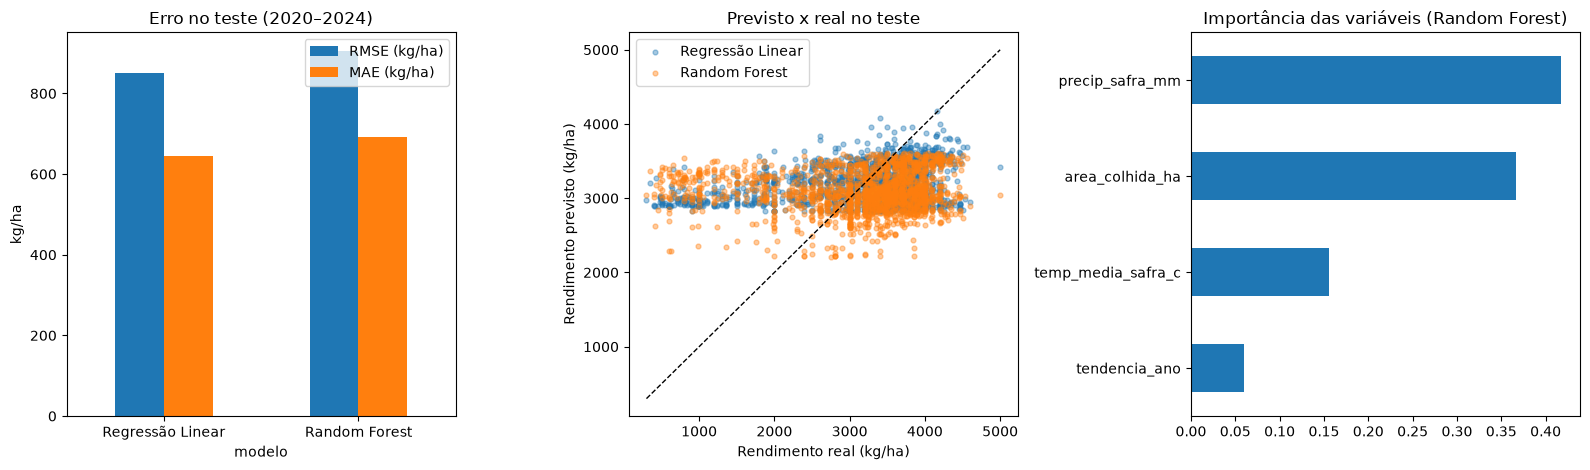

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))

# (a) comparação de erro
tabela[['RMSE (kg/ha)', 'MAE (kg/ha)']].plot.bar(ax=eixos[0], rot=0)
eixos[0].set_title('Erro no teste (2020–2024)')
eixos[0].set_ylabel('kg/ha')

# (b) previsto x real
for nome, p in preds.items():
    eixos[1].scatter(y_test, p, alpha=0.4, s=12, label=nome)
lim = [y_test.min(), y_test.max()]
eixos[1].plot(lim, lim, 'k--', lw=1)
eixos[1].set_xlabel('Rendimento real (kg/ha)')
eixos[1].set_ylabel('Rendimento previsto (kg/ha)')
eixos[1].set_title('Previsto x real no teste')
eixos[1].legend()

# (c) importância das variáveis (Random Forest)
rf = modelos['Random Forest']
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(ax=eixos[2])
eixos[2].set_title('Importância das variáveis (Random Forest)')

plt.tight_layout()
plt.savefig('figuras_modelos.png', dpi=120)
plt.show()

## 8. Conclusão dos modelos

**Resultados no teste (2020–2024):**

| Modelo | RMSE (kg/ha) | MAE (kg/ha) | R² |
|---|---|---|---|
| Regressão Linear | 850 | 646 | 0,07 |
| Random Forest | 906 | 693 | −0,06 |

Na validação cruzada feita só no treino (2008–2019), a Regressão Linear também foi melhor: RMSE de 626 ± 162 kg/ha, contra 693 ± 262 kg/ha da Random Forest.

**Escolha:** a Regressão Linear é o modelo mais adequado aqui. Ela ficou na frente nos dois testes e é mais simples de explicar ao produtor. A Random Forest variou mais entre as dobras e não ganhou no teste, mesmo captando relações não lineares.

**Leitura honesta:** os dois modelos explicam pouco da variação (R² próximo de zero). O erro médio de cerca de 650 a 850 kg/ha equivale a 20% a 28% do rendimento médio de 3.050 kg/ha. Isso não basta para orientar sozinho uma decisão de plantio ou venda. As causas prováveis são: o clima é do estado, e não do município; o teste tem só cinco anos, incluindo a seca de 2022, quando o rendimento mediano caiu para cerca de 2.040 kg/ha; e a área colhida só é conhecida depois da colheita.

**Próximos passos possíveis:** usar clima por município (com coordenadas das estações), incluir a área plantada no início da safra e testar um modelo de referência que usa só a média histórica, para medir o ganho real do modelo.

## 9. Texto analítico

- **Escolhas de modelo:** Regressão Linear como referência simples e interpretável, e Random Forest para captar relações não lineares. A Random Forest não superou a Linear, o que indica poucos dados para o ganho de complexidade.
- **Limitações:** clima do estado (não do município); área colhida só é conhecida após a colheita; teste com apenas cinco anos; dados de clima de estações que começam em 2008 (antes disso o Paraná quase não tem estações no INMET).
- **Vieses possíveis:** municípios pequenos e de agricultura familiar podem ter menos registros e estar longe das estações; o modelo tende a acertar mais onde a produção é grande e concentrada. Isso deve ser declarado na proposta.
- **Contribuição para a decisão:** no estágio atual, o modelo mostra que o clima da safra e a tendência tecnológica explicam pouco do rendimento no teste recente. Ele serve como ponto de partida e como alerta sobre a necessidade de dados mais locais, não como recomendação pronta ao produtor.